# Linear Algebra Technique: Projection of $\sin x$ on Span of  $\{1,x,x^2, x^3,x^4\}$

Many problems involve replacing a function by a simplified version that is easier to compute and analyze. One common approach is to approximate a function using a polynomial, very much like in Taylor series.

In this lab, we will focus on the functions $\sin(x)$ and $\cos(x)$, which arise naturally in many applications. These functions are also fundamental because a broad class of periodic functions can be represented as infinite sums of sine and cosine functions through the theory of Fourier series. Thus, understanding how to approximate sine and cosine is an important step toward understanding the approximation of more general functions.

To construct polynomial approximations, we consider the polynomial space
$$
P_n=
\{a_0+a_1x+
\cdots+a_nx^n \,|\, a_o, a_1, ..., a_n \in \mathbb{R}
\},$$
consisting of all polynomials of degree at most $n$.

To determine which polynomial provides the "best" approximation to a function $f(x)$, we introduce an inner product on functions:

$$
\langle f,g
\rangle
=
\int_a^b f(x)g(x)
\,dx.$$
This inner product allows us to view functions as vectors and polynomial spaces as subspaces of a larger function space.

The key idea comes directly from linear algebra. In Euclidean space, if a vector does not belong to a subspace, the closest vector in that subspace is obtained by orthogonal projection. In this lab, you will see that approximating functions is fundamentally the same problem as projecting vectors onto subspaces. The only difference is that the vectors are now functions, and the subspace consists of polynomials rather than vectors in $\mathbb{R}^n$.



In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

x = sp.symbols('x', real=True)

# Inner product using symbolic integration on [-pi, pi]
def ip(p1, p2):
    integrand = sp.expand(p1 * p2)
    return sp.integrate(integrand, (x, -sp.pi, sp.pi))

# Projection of u onto v: (ip(u,v)/ip(v,v)) * v
def Projection(u, v):
    denom = ip(v, v)
    if denom == 0:
        raise ZeroDivisionError("Attempted to project onto a zero-norm vector in this inner product.")
    return sp.simplify(ip(u, v) / denom * v)

In [2]:
w0, w1, w2, w3, w4 = 1, x, x**2, x**3, x**4

In [3]:
# v0 = w0, then scale by ip(v0,v0) as in original style
v0 = w0
v0 = sp.simplify(v0 / ip(v0, v0))
print("v0 =", sp.simplify(v0))

v0 = 1/(2*pi)


In [4]:
# v1 = w1 - Projection[w1, v0]
v1 = sp.simplify(w1 - Projection(w1, v0))
# scale as in the original style
v1 = sp.simplify(v1 / ip(v1, v1))
print("v1 =", sp.simplify(v1))

v1 = 3*x/(2*pi**3)


In [5]:
# v2 = w2 - Proj onto v0 and v1
v2 = sp.simplify(w2 - Projection(w2, v0) - Projection(w2, v1))
v2 = sp.simplify(v2 / ip(v2, v2))
print("v2 =", sp.simplify(v2))
print("v1 =", sp.simplify(v2))

v2 = 15*(3*x**2 - pi**2)/(8*pi**5)
v1 = 15*(3*x**2 - pi**2)/(8*pi**5)


In [6]:
# v3 = w3 - Proj onto v0, v1, v2
v3 = sp.simplify(w3 - Projection(w3, v0) - Projection(w3, v1) - Projection(w3, v2))
v3 = sp.simplify(v3 / ip(v3, v3))
print("v3 =", sp.simplify(v3))

v3 = (175*x**3 - 105*pi**2*x)/(8*pi**7)


In [7]:
# v4 = w4 - Proj onto v0, v1, v2, v3 (fixed)
v4 = sp.simplify(w4 - Projection(w4, v0) - Projection(w4, v1) - Projection(w4, v2) - Projection(w4, v3))
v4 = sp.simplify(v4 / ip(v4, v4))
print("v4 =", sp.simplify(v4))

v4 = 315*(35*x**4 - 30*pi**2*x**2 + 3*pi**4)/(128*pi**9)


In [8]:
b = sp.sin(x)
bcap = sp.simplify(Projection(b, v0) + Projection(b, v1) + Projection(b, v2) + Projection(b, v3) + Projection(b, v4))
print("bcap =", sp.simplify(bcap))

bcap = -x*(7*(15 - pi**2)*(5*x**2 - 3*pi**2) - 6*pi**4)/(2*pi**6)


In [9]:
poly_bcap = sp.Poly(sp.expand(bcap), x)
coeffs_desc = poly_bcap.all_coeffs()   # highest degree -> lowest
coeffs_asc = list(reversed(coeffs_desc))
F = [sp.N(c) for c in coeffs_asc]
print("Coefficient list F (ascending, from x^0 to x^{}):".format(poly_bcap.degree()), F)

Coefficient list F (ascending, from x^0 to x^3): [0, 0.856983327795250, 0, -0.0933876972831854]


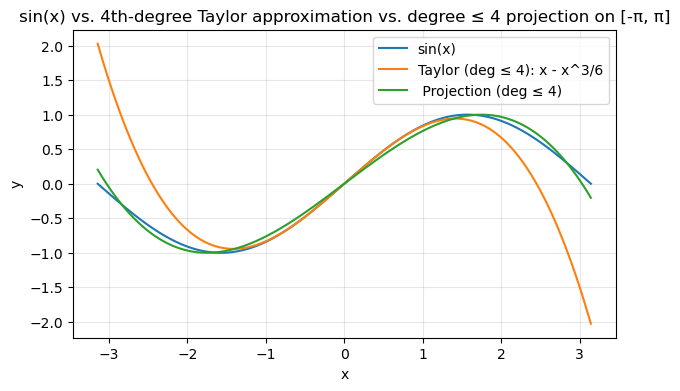

In [10]:
xx = np.linspace(-np.pi, np.pi, 1201)

def f_sin(xv):
    return np.sin(xv)

# Taylor up to degree 4 (sin has only odd powers => degree 3)
def taylor4(xv):
    return xv - (xv**3)/6.0

# Evaluate the symbolic polynomial bcap over the grid
bcap_fun = sp.lambdify(x, sp.expand(bcap), 'numpy')

plt.figure(figsize=(7,4))
plt.plot(xx, f_sin(xx), label='sin(x)')
plt.plot(xx, taylor4(xx), label='Taylor (deg ≤ 4): x - x^3/6')
plt.plot(xx, bcap_fun(xx), label=' Projection (deg ≤ 4)')
plt.title('sin(x) vs. 4th-degree Taylor approximation vs. degree ≤ 4 projection on [-π, π]')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
Error1 = sp.N(ip(b - bcap, b - bcap))
print("Error by least squares projection (deg ≤ 4):", Error1)

taylor = x - (x**3)/6
Error2 = sp.N(ip(b - taylor, b - taylor))
print("Error by Taylor (deg ≤ 4):", Error2)

print("Accuracy factor (Taylor / Projection):", sp.N(Error2 / Error1))

Error by least squares projection (deg ≤ 4): 0.0275839162396010
Error by Taylor (deg ≤ 4): 2.51851020006536
Accuracy factor (Taylor / Projection): 91.3035762648397


In [12]:
def orthogonal_basis(n):
    basis = []
    for i in range(n + 1):
        v = x**i
        for q in basis:
            v = sp.simplify(v - Projection(v, q))
        basis.append(sp.simplify(v))
    return basis

def project_function(f, n):
    basis = orthogonal_basis(n)
    return sp.simplify(sum(Projection(f, v) for v in basis))

for n in [5, 7]:
    f = sp.sin(x)
    p = project_function(f, n)
    t = sp.series(f, x, 0, n + 1).removeO()
    e1 = sp.N(ip(f - p, f - p))
    e2 = sp.N(ip(f - t, f - t))

    print("Degree:", n)
    print("Projection:", sp.collect(sp.expand(p), x))
    print("Taylor:", t)
    print("Projection error:", e1)
    print("Taylor error:", e2)
    print()

Degree: 5
Projection: x**5*(-72765/(8*pi**8) + 693/(8*pi**6) + 654885/(8*pi**10)) + x**3*(-363825/(4*pi**8) - 315/(4*pi**4) + 39375/(4*pi**6)) + x*(-16065/(8*pi**4) + 105/(8*pi**2) + 155925/(8*pi**6))
Taylor: x**5/120 - x**3/6 + x
Projection error: 0.000116168839090505
Taylor error: 0.118701845843008

Degree: 7
Projection: x**7*(-869593725/(16*pi**14) - 1216215/(8*pi**10) + 6435/(16*pi**8) + 111486375/(16*pi**12)) + x**5*(-178783605/(16*pi**10) - 9009/(16*pi**6) + 945945/(4*pi**8) + 1404728325/(16*pi**12)) + x**3*(-638512875/(16*pi**10) - 814275/(8*pi**6) + 3465/(16*pi**4) + 80405325/(16*pi**8)) + x*(-8783775/(16*pi**6) - 315/(16*pi**2) + 10395/pi**4 + 70945875/(16*pi**8))
Taylor: -x**7/5040 + x**5/120 - x**3/6 + x
Projection error: 1.53991006751067e-7
Taylor error: 0.00190248923839706



In [13]:
f = sp.cos(x)

p5 = project_function(f, 5)
t5 = sp.series(f, x, 0, 6).removeO()

e1 = sp.N(ip(f - p5, f - p5))
e2 = sp.N(ip(f - t5, f - t5))

print("Q3")
print("Projection:", sp.collect(sp.expand(p5), x))
print("Taylor:", t5)
print("Projection error:", e1)
print("Taylor error:", e2)

p6 = project_function(f, 6)
e3 = sp.N(ip(f - p6, f - p6))

print("\nQ4")
print("Improved projection:", sp.collect(sp.expand(p6), x))
print("Degree 5 projection error:", e1)
print("Degree 6 projection error:", e3)

Q3
Projection: x**4*(-1575/(4*pi**6) + 33075/(8*pi**8)) + x**2*(-14175/(4*pi**6) + 315/pi**4) - 105/(4*pi**2) + 2835/(8*pi**4)
Taylor: x**4/24 - x**2/2 + 1
Projection error: 0.00211745102260516
Taylor error: 0.639213736398988

Q4
Improved projection: x**6*(-31216185/(16*pi**12) - 63063/(16*pi**8) + 945945/(4*pi**10)) + x**4*(-2546775/(8*pi**8) + 79695/(16*pi**6) + 42567525/(16*pi**10)) + x**2*(-14189175/(16*pi**8) - 23625/(16*pi**4) + 103950/pi**6) - 38115/(8*pi**4) + 945/(16*pi**2) + 675675/(16*pi**6)
Degree 5 projection error: 0.00211745102260516
Degree 6 projection error: 4.78958437477803e-6
